In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install fvcore

In [3]:
from typing import Union

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import FloatTensor
from torch.autograd import Variable


import os
import numpy as np
import pandas as pd
import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader,TensorDataset,random_split,SubsetRandomSampler, ConcatDataset
import glob, os


import numpy as np
import torch
import torch.nn.functional as F

from torch import optim
from torch.autograd import Variable


from sklearn.model_selection import KFold
import itertools
import random
import math
from datetime import date
import time

torch.manual_seed(7)

In [4]:
# import torch
# import torch.nn as nn

# class DeepSet(nn.Module):
#     def __init__(self,
#                  infeatures,
#                  outfeatures,
#                  nencode_layers,
#                  ndecode_layers,
#                  hidden_units,
#                  dropout,
#                  pool_mode='cat_mean_max' # NEW: Default to richer pooling
#                  ):
#         super().__init__()

#         self.pool_mode = pool_mode

#         # --- 1. ENCODER ---
#         encoder_layers = []
#         for i in range(nencode_layers):
#             input_dim = infeatures if i == 0 else hidden_units

#             encoder_layers.append(nn.Linear(input_dim, hidden_units))
#             encoder_layers.append(nn.LayerNorm(hidden_units)) # NEW: Stability
#             encoder_layers.append(nn.ReLU())
#             if dropout > 0:
#                 encoder_layers.append(nn.Dropout(dropout))

#         self.encoder = nn.Sequential(*encoder_layers)

#         # --- 2. CALCULATE DECODER INPUT SIZE ---
#         # If we concat mean + max, the dimension doubles.
#         if pool_mode == 'cat_mean_max':
#             decoder_in_features = hidden_units * 2
#         elif pool_mode == 'cat_mean_max_min':
#             decoder_in_features = hidden_units * 3
#         else:
#             decoder_in_features = hidden_units

#         # --- 3. DECODER ---
#         decoder_layers = []
#         for i in range(ndecode_layers):
#             # First layer takes the aggregated vector (potentially larger)
#             din = decoder_in_features if i == 0 else hidden_units

#             if i == (ndecode_layers - 1):
#                 decoder_layers.append(nn.Linear(din, outfeatures))
#             else:
#                 decoder_layers.append(nn.Linear(din, hidden_units))
#                 decoder_layers.append(nn.LayerNorm(hidden_units)) # NEW: Stability
#                 decoder_layers.append(nn.ReLU())
#                 if dropout > 0:
#                     decoder_layers.append(nn.Dropout(dropout))

#         self.decoder = nn.Sequential(*decoder_layers)

#     def aggregate(self, x):
#         # x shape: (Batch, Points, Hidden)

#         if self.pool_mode == 'mean':
#             return torch.mean(x, dim=1)

#         elif self.pool_mode == 'max':
#             return torch.max(x, dim=1).values

#         elif self.pool_mode == 'sum':
#             return torch.sum(x, dim=1)

#         elif self.pool_mode == 'cat_mean_max':
#             # Returns (Batch, Hidden * 2)
#             # Captures both CENTER and EXTREMITY
#             mean_val = torch.mean(x, dim=1)
#             max_val = torch.max(x, dim=1).values
#             return torch.cat([mean_val, max_val], dim=1)

#         elif self.pool_mode == 'cat_mean_max_min':
#             # Returns (Batch, Hidden * 3)
#             # Captures Top, Bottom, and Center (Best for geometry)
#             mean_val = torch.mean(x, dim=1)
#             max_val = torch.max(x, dim=1).values
#             min_val = torch.min(x, dim=1).values
#             return torch.cat([mean_val, max_val, min_val], dim=1)

#         else:
#             raise ValueError(f"Unknown pool mode: {self.pool_mode}")

#     def forward(self, x):
#         # 1. Encode every point independently
#         # x: (B, N, 3) -> (B, N, Hidden)
#         x = self.encoder(x)

#         # 2. Aggregate points into a single cluster vector
#         # x: (B, N, Hidden) -> (B, Pooled_Dim)
#         x = self.aggregate(x)

#         # 3. Decode to final cluster representation
#         # x: (B, Pooled_Dim) -> (B, OutFeatures)
#         x = self.decoder(x)

#         return x

In [5]:
class DeepSet(nn.Module):
    def __init__(self,
                 infeatures,
                 outfeatures,
                 nencode_layers,
                 ndecode_layers,
                 hidden_units,
                 dropout,
                 pool_mode='cat_mean_max_min'
                 ):
        super().__init__()

        self.pool_mode = pool_mode

        # --- FIX: Input Batch Normalization ---
        # This takes tiny inputs (e.g., 0.001) and scales them to ~1.0
        # It learns a shift/scale parameter per coordinate (x, y, z)
        self.input_bn = nn.BatchNorm1d(infeatures)

        # --- 1. ENCODER ---
        encoder_layers = []
        for i in range(nencode_layers):
            input_dim = infeatures if i == 0 else hidden_units

            encoder_layers.append(nn.Linear(input_dim, hidden_units))
            # BatchNorm is usually better than LayerNorm for Point-based encoders
            # as it normalizes across the whole batch of points.
            encoder_layers.append(nn.BatchNorm1d(hidden_units))
            encoder_layers.append(nn.ReLU())
            if dropout > 0:
                encoder_layers.append(nn.Dropout(dropout))

        self.encoder = nn.Sequential(*encoder_layers)

        # --- 2. CALCULATE DECODER INPUT SIZE ---
        if pool_mode == 'cat_mean_max':
            decoder_in_features = hidden_units * 2
        elif pool_mode == 'cat_mean_max_min':
            decoder_in_features = hidden_units * 3
        else:
            decoder_in_features = hidden_units

        # --- 3. DECODER ---
        decoder_layers = []
        for i in range(ndecode_layers):
            din = decoder_in_features if i == 0 else hidden_units

            if i == (ndecode_layers - 1):
                decoder_layers.append(nn.Linear(din, outfeatures))
            else:
                decoder_layers.append(nn.Linear(din, hidden_units))
                # BatchNorm here too
                decoder_layers.append(nn.BatchNorm1d(hidden_units))
                decoder_layers.append(nn.ReLU())
                if dropout > 0:
                    decoder_layers.append(nn.Dropout(dropout))

        self.decoder = nn.Sequential(*decoder_layers)

    def aggregate(self, x):
        # (Same as before)
        if self.pool_mode == 'mean':
            return torch.mean(x, dim=1)
        elif self.pool_mode == 'max':
            return torch.max(x, dim=1).values
        elif self.pool_mode == 'cat_mean_max':
            mean_val = torch.mean(x, dim=1)
            max_val = torch.max(x, dim=1).values
            return torch.cat([mean_val, max_val], dim=1)
        elif self.pool_mode == 'cat_mean_max_min':
            mean_val = torch.mean(x, dim=1)
            max_val = torch.max(x, dim=1).values
            min_val = torch.min(x, dim=1).values
            return torch.cat([mean_val, max_val, min_val], dim=1)
        else:
            raise ValueError(f"Unknown pool mode: {self.pool_mode}")

    def forward(self, x):
        # x shape: (Batch, N_points, 3)

        # --- FIX: Apply Input Batch Norm ---
        # BatchNorm1d expects (Batch, Channels, Length) or (Batch, Channels)
        # We treat the points as part of the batch dimension for normalization
        # Reshape: (B, N, 3) -> (B*N, 3)
        B, N, C = x.size()
        x_flat = x.view(-1, C)

        # Normalize the raw coordinates!
        x_norm = self.input_bn(x_flat)

        # Run Encoder on normalized points
        # x_encoded: (B*N, Hidden)
        x_encoded = self.encoder(x_norm)

        # Reshape back to (B, N, Hidden) for aggregation
        x_encoded = x_encoded.view(B, N, -1)

        # Aggregate
        x_agg = self.aggregate(x_encoded)

        # Decoder
        out = self.decoder(x_agg)

        return out

In [6]:
import torch
import torch.nn as nn


class DeepSet(nn.Module):
    def __init__(self,
                 infeatures,
                 outfeatures,
                 nencode_layers,
                 ndecode_layers,
                 hidden_units,
                 dropout,
                 pool_mode='cat_mean_max_min'
                 ):
        super().__init__()

        self.pool_mode = pool_mode

        # -------- Encoder --------
        encoder_layers = []
        for i in range(nencode_layers):
            input_dim = infeatures if i == 0 else hidden_units

            encoder_layers.append(nn.Linear(input_dim, hidden_units))
            encoder_layers.append(nn.ReLU())

            if dropout > 0:
                encoder_layers.append(nn.Dropout(dropout))

        self.encoder = nn.Sequential(*encoder_layers)

        # -------- Decoder input size --------
        if pool_mode == 'cat_mean_max':
            decoder_in_features = hidden_units * 2
        elif pool_mode == 'cat_mean_max_min':
            decoder_in_features = hidden_units * 3
        else:
            decoder_in_features = hidden_units

        # -------- Decoder --------
        decoder_layers = []
        for i in range(ndecode_layers):
            din = decoder_in_features if i == 0 else hidden_units

            if i == (ndecode_layers - 1):
                decoder_layers.append(nn.Linear(din, outfeatures))
            else:
                decoder_layers.append(nn.Linear(din, hidden_units))
                decoder_layers.append(nn.ReLU())

                if dropout > 0:
                    decoder_layers.append(nn.Dropout(dropout))

        self.decoder = nn.Sequential(*decoder_layers)

    def aggregate(self, x):
        if self.pool_mode == 'mean':
            return torch.mean(x, dim=1)

        elif self.pool_mode == 'max':
            return torch.max(x, dim=1).values

        elif self.pool_mode == 'cat_mean_max':
            mean_val = torch.mean(x, dim=1)
            max_val = torch.max(x, dim=1).values
            return torch.cat([mean_val, max_val], dim=1)

        elif self.pool_mode == 'cat_mean_max_min':
            mean_val = torch.mean(x, dim=1)
            max_val = torch.max(x, dim=1).values
            min_val = torch.min(x, dim=1).values
            return torch.cat([mean_val, max_val, min_val], dim=1)

        else:
            raise ValueError(f"Unknown pool mode: {self.pool_mode}")

    def forward(self, x):
        # x shape: (B, N, 3)

        B, N, C = x.size()

        # Flatten for encoder
        x_flat = x.view(-1, C)

        # Encode
        x_encoded = self.encoder(x_flat)

        # Restore shape
        x_encoded = x_encoded.view(B, N, -1)

        # Aggregate
        x_agg = self.aggregate(x_encoded)

        # Decode
        out = self.decoder(x_agg)

        return out

In [7]:
# class DeepSet(nn.Module):

#     def __init__(self,infeatures,outfeatures,nencode_layers,ndecode_layers,hidden_units,dropout,invariant_type='sum'):
#         super().__init__()
#         enocoder_layers = []
#         decoder_layers = []

#         for i in range(nencode_layers):
#             if i == 0:
#                 enocoder_layers.append(nn.Linear(infeatures, hidden_units))
#                 enocoder_layers.append(nn.Dropout(dropout))
#                 enocoder_layers.append(nn.ReLU())

#             else:
#                 enocoder_layers.append(nn.Linear(hidden_units, hidden_units))
#                 enocoder_layers.append(nn.Dropout(dropout))
#                 enocoder_layers.append(nn.ReLU())


#         for i in range(ndecode_layers):
# #             decoder_layers.append(nn.Linear(hidden_units, hidden_units))
#             if i == (ndecode_layers-1):
#                 decoder_layers.append(nn.Linear(hidden_units,outfeatures))

#             else:
#                 decoder_layers.append(nn.Linear(hidden_units, hidden_units))
#                 decoder_layers.append(nn.Dropout(dropout))
#                 decoder_layers.append(nn.ReLU())

#         self.encoder = nn.Sequential(*enocoder_layers)
#         self.decoder = nn.Sequential(*decoder_layers)
#         self.invariant_type = invariant_type


#     def invariant_func(self,x,invariant_type):

#         if invariant_type == "sum":
#             invariant_t = torch.sum(x, dim=1, keepdim=True)
#         elif invariant_type == "mean":
#             invariant_t = torch.mean(x, dim=1, keepdim=True)
#         elif invariant_type == "median":
#             invariant_t = torch.median(x, dim=1, keepdim=True).values
#         elif invariant_type == "min":
#             invariant_t = torch.min(x, dim=1, keepdim=True).values
#         elif invariant_type == "max":
#             invariant_t = torch.max(x, dim=1, keepdim=True).values
#         return invariant_t

#     def forward(self,x):
#         x = self.encoder(x)
#         x = self.invariant_func(x,self.invariant_type)
#         x = self.decoder(x)

#         return x


In [8]:
# import torch
# import torch.nn as nn

# class GADS(nn.Module):
#     def __init__(self,
#                  num_clusters,
#                  cluster_indices,
#                  deepset_infeatures,
#                  deepset_outfeatures,
#                  deepset_nencode_layers,
#                  deepset_ndecode_layers,
#                  deepset_hidden_units,
#                  dropout,
#                  num_heads,
#                  multihead_outdim,
#                  final_out,
#                  final_ndecode_layers,
#                  invariant_type='mean'
#                 ):
#         super().__init__()

#         assert deepset_outfeatures == multihead_outdim, \
#             "deepset_outfeatures must equal multihead_outdim for attention to work."

#         self.num_clusters = num_clusters
#         self.cluster_indices = cluster_indices

#         # 1. DeepSets (Feature Extractors per Cluster)
#         self.deepsets = nn.ModuleList([
#             DeepSet(deepset_infeatures,
#                     deepset_outfeatures,
#                     deepset_nencode_layers,
#                     deepset_ndecode_layers,
#                     deepset_hidden_units,
#                     dropout,
#                     pool_mode='cat_mean_max')
#             for _ in range(num_clusters)
#         ])


#         # 2. Attention Mechanism (Inter-cluster relationships)
#         self.multihead_attn = nn.MultiheadAttention(
#             embed_dim=multihead_outdim,
#             num_heads=num_heads,
#             batch_first=True
#         )

#         self.pre_attn_ln = nn.LayerNorm(multihead_outdim)
#         self.post_attn_ln = nn.LayerNorm(multihead_outdim)

#         # --- ARCHITECTURE FIXES FOR PITCH ---

#         # Calculate the input size for the final decoder
#         # Part A: Flattened Tokens (We do NOT pool anymore)
#         # Size: num_clusters * 128
#         token_flat_dim = num_clusters * multihead_outdim

#         # Part B: Explicit Centroids (Geometric Skeleton)
#         # Size: num_clusters * 3 (x, y, z)
#         centroid_flat_dim = num_clusters * 3

#         # Total Input Features to Decoder
#         fin = token_flat_dim + centroid_flat_dim

#         # 3. Final Decoder
#         final_decoder_layers = []
#         if final_ndecode_layers == 1:
#             final_decoder_layers.append(nn.Linear(fin, final_out))
#         else:
#             for i in range(final_ndecode_layers):
#                 if i == 0:
#                     final_decoder_layers.append(nn.Linear(fin, fin // 2)) # Shrink slightly
#                     final_decoder_layers.append(nn.ReLU())
#                     current_dim = fin // 2
#                 elif i == final_ndecode_layers - 1:
#                     final_decoder_layers.append(nn.Linear(current_dim, final_out))
#                 else:
#                     final_decoder_layers.append(nn.Linear(current_dim, current_dim))
#                     final_decoder_layers.append(nn.Dropout(dropout))
#                     final_decoder_layers.append(nn.ReLU())

#         self.decoder_layer = nn.Sequential(*final_decoder_layers)


#     def forward(self, x):
#         # x: (B, N, 3)
#         batch_size = x.size(0)

#         # 1. Prepare Inputs per Cluster
#         x_list = [x[:, idxs, :] for idxs in self.cluster_indices]

#         # --- FIX: Calculate Centroids Explicitly ---
#         # This captures the "Macro" geometry (e.g., where is the mouth relative to the eyes?)
#         # centroids shape: List of (B, 3)
#         centroids_list = [cluster_pts.mean(dim=1) for cluster_pts in x_list]

#         # Stack and Flatten Centroids: (B, C*3)
#         centroids_flat = torch.stack(centroids_list, dim=1).reshape(batch_size, -1)

#         # 2. DeepSet Processing
#         cluster_values = [ds(x_list[i]) for i, ds in enumerate(self.deepsets)]

#         # Ensure (B, F)
#         cluster_values = [cv.squeeze(1) if cv.dim() == 3 else cv for cv in cluster_values]

#         # Stack for Attention: (B, C, 128)
#         tokens = torch.stack(cluster_values, dim=1)

#         # 3. Attention Block
#         tokens = self.pre_attn_ln(tokens)
#         attn_out, _ = self.multihead_attn(tokens, tokens, tokens)
#         tokens = self.post_attn_ln(tokens + attn_out)  # (B, C, 128)

#         # --- FIX: Flatten Tokens instead of Pooling ---
#         # Preserves the identity of each cluster (Eye vs Mouth)
#         tokens_flat = tokens.reshape(batch_size, -1)  # (B, C*128)

#         # 4. Concatenate Features + Geometry
#         # The decoder now sees the "Semantic Features" AND the "Skeletal Position"
#         combined_input = torch.cat([tokens_flat, centroids_flat], dim=1)

#         # 5. Final Prediction
#         out = self.decoder_layer(combined_input)  # (B, 6)

#         return out

In [9]:
import torch
import torch.nn as nn


class GADS(nn.Module):
    def __init__(self,
                 num_clusters,
                 cluster_indices,
                 deepset_infeatures,
                 deepset_outfeatures,
                 deepset_nencode_layers,
                 deepset_ndecode_layers,
                 deepset_hidden_units,
                 dropout,
                 num_heads,
                 multihead_outdim,
                 final_out=3,
                 shared_ndecode_layers=2,
                 head_hidden=64,
                 attn_dropout=0.2,
                 token_drop_p=0.1,
                 pool_mode="mean_max"   # "mean" or "mean_max"
                 ):
        super().__init__()

        assert deepset_outfeatures == multihead_outdim, \
            "deepset_outfeatures must equal multihead_outdim (or add a projection)."

        self.num_clusters = num_clusters
        self.cluster_indices = cluster_indices
        self.token_drop_p = token_drop_p
        self.pool_mode = pool_mode

        # ---------------------------
        # 1. Per-cluster DeepSets
        # ---------------------------
        self.deepsets = nn.ModuleList([
            DeepSet(
                deepset_infeatures,
                deepset_outfeatures,
                deepset_nencode_layers,
                deepset_ndecode_layers,
                deepset_hidden_units,
                dropout,
                pool_mode='cat_mean_max'
            )
            for _ in range(num_clusters)
        ])

        # ---------------------------
        # 2. Attention block
        # ---------------------------
        self.multihead_attn = nn.MultiheadAttention(
            embed_dim=multihead_outdim,
            num_heads=num_heads,
            dropout=attn_dropout,
            batch_first=True
        )

        self.pre_attn_ln = nn.LayerNorm(multihead_outdim)
        self.post_attn_ln = nn.LayerNorm(multihead_outdim)
        self.attn_resid_dropout = nn.Dropout(dropout)

        # ---------------------------
        # 3. Geometry branch
        # compact geometry:
        # mean(3) + std(3) + eigvals(3) = 9
        # ---------------------------
        geom_dim = 9
        pooled_dim = multihead_outdim if pool_mode == "mean" else (2 * multihead_outdim)
        fused_dim = pooled_dim + geom_dim

        self.geom_dropout = nn.Dropout(dropout)
        self.pre_shared_dropout = nn.Dropout(dropout)

        # ---------------------------
        # 4. Shared decoder trunk
        # ---------------------------
        shared_layers = []
        cur = fused_dim

        for i in range(shared_ndecode_layers - 1):
            nxt = max(cur // 2, head_hidden)
            shared_layers += [
                nn.Linear(cur, nxt),
                nn.LayerNorm(nxt),
                nn.ReLU(),
                nn.Dropout(dropout)
            ]
            cur = nxt

        self.shared_decoder = nn.Sequential(*shared_layers) if len(shared_layers) > 0 else nn.Identity()
        shared_out_dim = cur

        # ---------------------------
        # 5. Separate heads
        # ---------------------------
        self.yaw_head = nn.Sequential(
            nn.Linear(shared_out_dim, head_hidden),
            nn.LayerNorm(head_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, 1)
        )

        self.pitch_head = nn.Sequential(
           nn.Linear(shared_out_dim, head_hidden),
            nn.LayerNorm(head_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, 1)
        )

        self.roll_head = nn.Sequential(
            nn.Linear(shared_out_dim, head_hidden),
            nn.LayerNorm(head_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, 1)
        )

    def _cov_eigvals(self, centroids):
        # centroids: (B, C, 3)
        B, C, _ = centroids.shape
        mean = centroids.mean(dim=1, keepdim=True)
        X = centroids - mean
        cov = torch.bmm(X.transpose(1, 2), X) / (C - 1 + 1e-6)  # (B,3,3)

        # normalize covariance by trace for scale stability
        tr = cov.diagonal(dim1=-2, dim2=-1).sum(-1, keepdim=True).clamp_min(1e-6)
        cov = cov / tr.view(B, 1, 1)

        eigvals = torch.linalg.eigvalsh(cov)  # (B,3)
        return eigvals

    def _token_dropout(self, tokens):
        # tokens: (B, C, F)
        if (not self.training) or self.token_drop_p <= 0:
            return tokens

        B, C, F = tokens.shape
        keep = (torch.rand(B, C, device=tokens.device) > self.token_drop_p).float().unsqueeze(-1)

        # ensure at least one token stays
        all_dropped = (keep.sum(dim=1, keepdim=True) == 0).float()
        keep = keep + all_dropped

        return tokens * keep

    def subsample_cluster_pts(self, cluster_pts, progress: float, min_keep=1):
        # cluster_pts: (B, K, 3)
        B, K, D = cluster_pts.shape

        if K <= min_keep:
            return cluster_pts

        # min_keep -> K as progress 0 -> 1
        k_keep = int(round((1 - progress) * min_keep + progress * K))
        k_keep = max(min_keep, min(k_keep, K))

        if k_keep == K:
            return cluster_pts

        sel = torch.randperm(K, device=cluster_pts.device)[:k_keep]
        return cluster_pts[:, sel, :]

    def forward_features(self, x, progress: float = None):
        # x: (B, N, 3)
        B = x.size(0)

        # 1. cluster split
        x_list = [x[:, idxs, :] for idxs in self.cluster_indices]

        # 2. curriculum landmark subsampling
        # if self.training and (progress is not None):
        #     progress = float(max(0.0, min(1.0, progress)))
        #     x_list = [self.subsample_cluster_pts(pts, progress, min_keep=1) for pts in x_list]

        # 3. centroids
        centroids = torch.stack([pts.mean(dim=1) for pts in x_list], dim=1)  # (B,C,3)

        # 4. compact geometry
        c_mean = centroids.mean(dim=1)          # (B,3)
        c_std = centroids.std(dim=1)            # (B,3)
        eigvals = self._cov_eigvals(centroids)  # (B,3)
        geom = torch.cat([c_mean, c_std, eigvals], dim=1)  # (B,9)
        geom = self.geom_dropout(geom)

        # 5. DeepSet tokens
        cluster_values = [ds(x_list[i]) for i, ds in enumerate(self.deepsets)]
        cluster_values = [cv.squeeze(1) if cv.dim() == 3 else cv for cv in cluster_values]
        tokens = torch.stack(cluster_values, dim=1)  # (B,C,F)

        # 6. token dropout
        tokens = self._token_dropout(tokens)

        # 7. attention with norm + residual
        tokens_ln = self.pre_attn_ln(tokens)
        attn_out, _ = self.multihead_attn(tokens_ln, tokens_ln, tokens_ln)
        tokens = self.post_attn_ln(tokens + self.attn_resid_dropout(attn_out))

        # 8. token pooling
        if self.pool_mode == "mean":
            pooled = tokens.mean(dim=1)
        else:
            pooled = torch.cat([tokens.mean(dim=1), tokens.max(dim=1).values], dim=1)

        # 9. fused representation
        fused = torch.cat([pooled, geom], dim=1)
        fused = self.pre_shared_dropout(fused)

        # 10. shared features
        shared = self.shared_decoder(fused)
        return shared

    def forward(self, x, progress: float = None):
        shared = self.forward_features(x, progress=progress)

        yaw = self.yaw_head(shared)
        pitch = self.pitch_head(shared)
        roll = self.roll_head(shared)

        out = torch.cat([yaw, pitch, roll], dim=1)  # (B,3)
        return out

In [10]:
# import torch
# import torch.nn as nn


# class GADS(nn.Module):
#     def __init__(self,
#                  num_clusters,
#                  cluster_indices,
#                  deepset_infeatures,
#                  deepset_outfeatures,
#                  deepset_nencode_layers,
#                  deepset_ndecode_layers,
#                  deepset_hidden_units,
#                  dropout,
#                  num_heads,
#                  multihead_outdim,
#                  final_out=3,
#                  shared_ndecode_layers=2,
#                  head_hidden=64,
#                  attn_dropout=0.2,
#                  token_drop_p=0.1,
#                  pool_mode="mean_max"   # "mean" or "mean_max"
#                  ):
#         super().__init__()

#         assert deepset_outfeatures == multihead_outdim, \
#             "deepset_outfeatures must equal multihead_outdim (or add a projection)."

#         self.num_clusters = num_clusters
#         self.cluster_indices = cluster_indices
#         self.token_drop_p = token_drop_p
#         self.pool_mode = pool_mode

#         # ---------------------------
#         # 1. Per-cluster DeepSets
#         # ---------------------------
#         self.deepsets = nn.ModuleList([
#             DeepSet(
#                 deepset_infeatures,
#                 deepset_outfeatures,
#                 deepset_nencode_layers,
#                 deepset_ndecode_layers,
#                 deepset_hidden_units,
#                 dropout,
#                 pool_mode='cat_mean_max'
#             )
#             for _ in range(num_clusters)
#         ])

#         # ---------------------------
#         # 2. Attention block
#         # ---------------------------
#         self.multihead_attn = nn.MultiheadAttention(
#             embed_dim=multihead_outdim,
#             num_heads=num_heads,
#             dropout=attn_dropout,
#             batch_first=True
#         )

#         self.pre_attn_ln = nn.LayerNorm(multihead_outdim)
#         self.post_attn_ln = nn.LayerNorm(multihead_outdim)
#         self.attn_resid_dropout = nn.Dropout(dropout)

#         # ---------------------------
#         # 2.5 FFN block after attention
#         # LayerNorm -> Linear(F -> 2F) -> ReLU -> Linear(2F -> F) + residual
#         # ---------------------------
#         self.ffn_ln = nn.LayerNorm(multihead_outdim)

#         self.ffn = nn.Sequential(
#             nn.Linear(multihead_outdim, 2 * multihead_outdim),
#             nn.ReLU(),
#             nn.Linear(2 * multihead_outdim, multihead_outdim)
#         )

#         self.ffn_resid_dropout = nn.Dropout(dropout)

#         # ---------------------------
#         # 3. Geometry branch
#         # compact geometry:
#         # mean(3) + std(3) + eigvals(3) = 9
#         # ---------------------------
#         geom_dim = 9
#         pooled_dim = multihead_outdim if pool_mode == "mean" else (2 * multihead_outdim)
#         fused_dim = pooled_dim + geom_dim

#         self.geom_dropout = nn.Dropout(dropout)
#         self.pre_shared_dropout = nn.Dropout(dropout)

#         # ---------------------------
#         # 4. Shared decoder trunk
#         # ---------------------------
#         shared_layers = []
#         cur = fused_dim

#         for i in range(shared_ndecode_layers - 1):
#             nxt = max(cur // 2, head_hidden)
#             shared_layers += [
#                 nn.Linear(cur, nxt),
#                 nn.LayerNorm(nxt),
#                 nn.ReLU(),
#                 nn.Dropout(dropout)
#             ]
#             cur = nxt

#         self.shared_decoder = nn.Sequential(*shared_layers) if len(shared_layers) > 0 else nn.Identity()
#         shared_out_dim = cur

#         # ---------------------------
#         # 5. Separate heads
#         # ---------------------------
#         self.yaw_head = nn.Sequential(
#             nn.Linear(shared_out_dim, head_hidden),
#             nn.LayerNorm(head_hidden),
#             nn.ReLU(),
#             nn.Dropout(dropout),
#             nn.Linear(head_hidden, 1)
#         )

#         self.pitch_head = nn.Sequential(
#             nn.Linear(shared_out_dim, head_hidden),
#             nn.LayerNorm(head_hidden),
#             nn.ReLU(),
#             nn.Dropout(dropout),
#             nn.Linear(head_hidden, 1)
#         )

#         self.roll_head = nn.Sequential(
#             nn.Linear(shared_out_dim, head_hidden),
#             nn.LayerNorm(head_hidden),
#             nn.ReLU(),
#             nn.Dropout(dropout),
#             nn.Linear(head_hidden, 1)
#         )

#     def _cov_eigvals(self, centroids):
#         # centroids: (B, C, 3)
#         B, C, _ = centroids.shape
#         mean = centroids.mean(dim=1, keepdim=True)
#         X = centroids - mean
#         cov = torch.bmm(X.transpose(1, 2), X) / (C - 1 + 1e-6)  # (B,3,3)

#         # normalize covariance by trace for scale stability
#         tr = cov.diagonal(dim1=-2, dim2=-1).sum(-1, keepdim=True).clamp_min(1e-6)
#         cov = cov / tr.view(B, 1, 1)

#         eigvals = torch.linalg.eigvalsh(cov)  # (B,3)
#         return eigvals

#     def _token_dropout(self, tokens):
#         # tokens: (B, C, F)
#         if (not self.training) or self.token_drop_p <= 0:
#             return tokens

#         B, C, F = tokens.shape
#         keep = (torch.rand(B, C, device=tokens.device) > self.token_drop_p).float().unsqueeze(-1)

#         # ensure at least one token stays
#         all_dropped = (keep.sum(dim=1, keepdim=True) == 0).float()
#         keep = keep + all_dropped

#         return tokens * keep

#     def subsample_cluster_pts(self, cluster_pts, progress: float, min_keep=1):
#         # cluster_pts: (B, K, 3)
#         B, K, D = cluster_pts.shape

#         if K <= min_keep:
#             return cluster_pts

#         # min_keep -> K as progress 0 -> 1
#         k_keep = int(round((1 - progress) * min_keep + progress * K))
#         k_keep = max(min_keep, min(k_keep, K))

#         if k_keep == K:
#             return cluster_pts

#         sel = torch.randperm(K, device=cluster_pts.device)[:k_keep]
#         return cluster_pts[:, sel, :]

#     def forward_features(self, x, progress: float = None):
#         # x: (B, N, 3)
#         B = x.size(0)

#         # 1. cluster split
#         x_list = [x[:, idxs, :] for idxs in self.cluster_indices]

#         # 2. curriculum landmark subsampling
#         # if self.training and (progress is not None):
#         #     progress = float(max(0.0, min(1.0, progress)))
#         #     x_list = [self.subsample_cluster_pts(pts, progress, min_keep=1) for pts in x_list]

#         # 3. centroids
#         centroids = torch.stack([pts.mean(dim=1) for pts in x_list], dim=1)  # (B,C,3)

#         # 4. compact geometry
#         c_mean = centroids.mean(dim=1)           # (B,3)
#         c_std = centroids.std(dim=1)             # (B,3)
#         eigvals = self._cov_eigvals(centroids)   # (B,3)
#         geom = torch.cat([c_mean, c_std, eigvals], dim=1)  # (B,9)
#         geom = self.geom_dropout(geom)

#         # 5. DeepSet tokens
#         cluster_values = [ds(x_list[i]) for i, ds in enumerate(self.deepsets)]
#         cluster_values = [cv.squeeze(1) if cv.dim() == 3 else cv for cv in cluster_values]
#         tokens = torch.stack(cluster_values, dim=1)  # (B,C,F)

#         # 6. token dropout
#         tokens = self._token_dropout(tokens)

#         # 7. attention with norm + residual
#         tokens_ln = self.pre_attn_ln(tokens)

#         attn_out, _ = self.multihead_attn(
#             tokens_ln,
#             tokens_ln,
#             tokens_ln,
#             need_weights=False
#         )

#         tokens = self.post_attn_ln(
#             tokens + self.attn_resid_dropout(attn_out)
#         )

#         # 8. FFN after attention
#         # This lets each token transform after exchanging information through attention.
#         ffn_in = self.ffn_ln(tokens)
#         ffn_out = self.ffn(ffn_in)

#         tokens = tokens + self.ffn_resid_dropout(ffn_out)

#         # 9. token pooling
#         if self.pool_mode == "mean":
#             pooled = tokens.mean(dim=1)
#         else:
#             pooled = torch.cat(
#                 [tokens.mean(dim=1), tokens.max(dim=1).values],
#                 dim=1
#             )

#         # 10. fused representation
#         fused = torch.cat([pooled, geom], dim=1)
#         fused = self.pre_shared_dropout(fused)

#         # 11. shared features
#         shared = self.shared_decoder(fused)
#         return shared

#     def forward(self, x, progress: float = None):
#         shared = self.forward_features(x, progress=progress)

#         yaw = self.yaw_head(shared)
#         pitch = self.pitch_head(shared)
#         roll = self.roll_head(shared)

#         out = torch.cat([yaw, pitch, roll], dim=1)  # (B,3)
#         return out

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class Engine:
    def __init__(self, model, optimizer, total_steps, min_keep=1, pitch_weight=1.5):
        self.model = model
        self.optimizer = optimizer
        self.total_steps = total_steps
        self.global_step = 0
        self.min_keep = min_keep
        self.pitch_weight = pitch_weight

        # better for regression than pure MSE in many pose tasks
        self.base_loss = nn.SmoothL1Loss()

    def weighted_pose_loss(self, yhat, y):
        """
        yhat, y: (B, 3)
        Expected order: [yaw, pitch, roll]
        """
        loss_yaw = self.base_loss(yhat[:, 1], y[:, 1])
        loss_pitch = self.base_loss(yhat[:, 0], y[:, 0])
        loss_roll = self.base_loss(yhat[:, 2], y[:, 2])

        loss = loss_yaw + self.pitch_weight * loss_pitch + loss_roll

        return loss, {
            "yaw_loss": loss_yaw.item(),
            "pitch_loss": loss_pitch.item(),
            "roll_loss": loss_roll.item(),
        }

    @staticmethod
    def mae_per_angle(yhat, y):
        """
        Returns mean absolute error for yaw, pitch, roll.
        """
        mae_yaw = F.l1_loss(yhat[:, 1], y[:, 1])
        mae_pitch = F.l1_loss(yhat[:, 0], y[:, 0])
        mae_roll = F.l1_loss(yhat[:, 2], y[:, 2])

        mae_mean = (mae_yaw + mae_pitch + mae_roll) / 3.0

        return mae_mean, {
            "yaw_mae": mae_yaw.item(),
            "pitch_mae": mae_pitch.item(),
            "roll_mae": mae_roll.item(),
        }

    def train(self, data_loader):
        self.model.train()

        final_loss = 0.0
        final_yaw = 0.0
        final_pitch = 0.0
        final_roll = 0.0

        for data in data_loader:
            x = data["landmark"]
            y = data["pose"]

            if torch.cuda.is_available():
                x = x.cuda(non_blocking=True)
                y = y.cuda(non_blocking=True)

            progress = progress_cosine(self.global_step, self.total_steps)

            self.optimizer.zero_grad()

            yhat = self.model(x, progress=progress)
            loss, loss_dict = self.weighted_pose_loss(yhat, y)

            loss.backward()
            #torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            self.global_step += 1

            final_loss += loss.item()
            final_yaw += loss_dict["yaw_loss"]
            final_pitch += loss_dict["pitch_loss"]
            final_roll += loss_dict["roll_loss"]

        n = len(data_loader)
        return {
            "loss": final_loss / n,
            "yaw_loss": final_yaw / n,
            "pitch_loss": final_pitch / n,
            "roll_loss": final_roll / n,
        }

    def evaluate(self, data_loader):
        self.model.eval()

        final_loss = 0.0
        final_yaw = 0.0
        final_pitch = 0.0
        final_roll = 0.0

        final_mae = 0.0
        final_yaw_mae = 0.0
        final_pitch_mae = 0.0
        final_roll_mae = 0.0

        with torch.no_grad():
            for data in data_loader:
                x = data["landmark"]
                y = data["pose"]

                if torch.cuda.is_available():
                    x = x.cuda(non_blocking=True)
                    y = y.cuda(non_blocking=True)

                yhat = self.model(x, progress=None)

                loss, loss_dict = self.weighted_pose_loss(yhat, y)
                mae, mae_dict = self.mae_per_angle(yhat, y)

                final_loss += loss.item()
                final_yaw += loss_dict["yaw_loss"]
                final_pitch += loss_dict["pitch_loss"]
                final_roll += loss_dict["roll_loss"]

                final_mae += mae.item()
                final_yaw_mae += mae_dict["yaw_mae"]
                final_pitch_mae += mae_dict["pitch_mae"]
                final_roll_mae += mae_dict["roll_mae"]

        n = len(data_loader)
        return {
            "loss": final_loss / n,
            "yaw_loss": final_yaw / n,
            "pitch_loss": final_pitch / n,
            "roll_loss": final_roll / n,
            "mae": final_mae / n,
            "yaw_mae": final_yaw_mae / n,
            "pitch_mae": final_pitch_mae / n,
            "roll_mae": final_roll_mae / n,
        }

In [12]:
def init_weights(m):
    if isinstance(m, nn.Linear):
        torch.nn.init.xavier_uniform_(m.weight)
        m.bias.data.fill_(0.01)

In [13]:
# model = GADS(
#         infeatures=3,
#         outfeatures=3,
#         nencode_layers=1,
#         ndecode_layers=1,
#         hidden_units=8,
#         dropout=0,
#         invariant_type="sum"
#     )
# for x,y in train_loader:
# #     query, keys, values = model(x)
#     yhat = model(x)
#     print(F.l1_loss(yhat,y))
#     break

# print(query.shape,keys.shape,values.shape)

In [14]:
def mk_dir(dir):
    try:
        os.mkdir( dir )
    except OSError:
        pass

In [15]:
# class HeadPoseDataset(torch.utils.data.Dataset):

#     def __init__(self,
#                  raw_data):
#         self.landmarks = torch.tensor(raw_data["landmarks"],dtype= torch.float32)
#         self.image = torch.tensor(raw_data["image"],dtype= torch.float32)
#         self.image = self.image.permute(0,3,1,2)
#         #print(self.image.shape)
#         self.pose = torch.tensor(raw_data["pose"], dtype= torch.float32)


#     def __len__(self):
#         return self.pose.shape[0]

#     def __getitem__(self, index):

#         image = self.image[index]
#         pose     =  self.pose[index]
#         landmark = self.landmarks[index]

#         sample = {
#                 "landmark":landmark,

#                 "pose"  : pose
#             }

#         return sample

In [16]:
class HeadPoseDataset(torch.utils.data.Dataset):

    def __init__(self,
                 raw_data):
        self.landmarks = torch.tensor(raw_data["landmark"],dtype= torch.float32)

        #print(self.image.shape)
        #self.gt_mat = raw_data["gt_mat"]
        self.cont_labels= raw_data["pose"]

    def __len__(self):
        return self.cont_labels.shape[0]
        print(cont_labels.shape[0])

    def __getitem__(self, index):

        #image = self.image[index]
        #pose     =  self.pose[index]
        landmark = self.landmarks[index]
        #gt_mat = self.gt_mat[index]
        cont_labels = self.cont_labels[index]

        sample = {
                "landmark":landmark,

                "pose":cont_labels

            }

        return sample

In [17]:
import torch
import torch.nn as nn


class HeadPoseDataset(torch.utils.data.Dataset):

    def __init__(self,
                 raw_data,
                 augment=False,
                 jitter_std=0.0075,   # 0.75% of coordinate range
                 flip_prob=0.5,
                 flip_x_mode="auto",  # "auto", "unit", or "centered"
                 pose_order=("yaw", "pitch", "roll"),
                 flip_pairs=None):
        """
        raw_data["landmark"]: shape (N, num_landmarks, 3)
        raw_data["pose"]: shape (N, 3), assumed [yaw, pitch, roll]

        augment=True  -> training only
        augment=False -> validation/test only

        jitter_std:
            0.005 = 0.5%
            0.01  = 1%

        flip_pairs:
            Optional list of left-right landmark index pairs.
            Example: [(left_eye_idx, right_eye_idx), ...]
            If provided, landmarks are swapped after horizontal flip.
        """

        self.landmarks = torch.tensor(raw_data["landmark"], dtype=torch.float32)
        self.cont_labels = torch.tensor(raw_data["pose"], dtype=torch.float32)

        self.augment = augment
        self.jitter_std = jitter_std
        self.flip_prob = flip_prob
        self.flip_x_mode = flip_x_mode
        self.flip_pairs = flip_pairs

        self.yaw_idx = pose_order.index("yaw")
        self.pitch_idx = pose_order.index("pitch")
        self.roll_idx = pose_order.index("roll")

    def __len__(self):
        return self.cont_labels.shape[0]

    def _gaussian_jitter(self, landmark):
        """
        Add small Gaussian noise to normalized coordinates.
        Noise strength is relative to each sample's coordinate range.
        """
        if self.jitter_std <= 0:
            return landmark

        coord_range = landmark.max(dim=0).values - landmark.min(dim=0).values
        coord_range = coord_range.clamp_min(1e-6)

        noise = torch.randn_like(landmark) * coord_range.view(1, -1) * self.jitter_std

        return landmark + noise

    def _horizontal_flip(self, landmark, pose):
        """
        Horizontal flip with head-pose angle correction.

        Assuming pose = [yaw, pitch, roll]:

        yaw   -> -yaw
        pitch ->  pitch
        roll  -> -roll
        """

        if torch.rand(1).item() > self.flip_prob:
            return landmark, pose

        x = landmark[:, 0].clone()

        if self.flip_x_mode == "unit":
            # For x normalized to [0, 1]
            landmark[:, 0] = 1.0 - x

        elif self.flip_x_mode == "centered":
            # For x centered around 0
            landmark[:, 0] = -x

        else:
            # Auto-detect
            if x.min() >= 0.0 and x.max() <= 1.0:
                landmark[:, 0] = 1.0 - x
            else:
                landmark[:, 0] = -x

        # Optional: swap left/right landmark indices if you know the pairs
        if self.flip_pairs is not None:
            for left_idx, right_idx in self.flip_pairs:
                temp = landmark[left_idx].clone()
                landmark[left_idx] = landmark[right_idx]
                landmark[right_idx] = temp

        # Pose sign correction
        pose[self.yaw_idx] = -pose[self.yaw_idx]
        pose[self.roll_idx] = -pose[self.roll_idx]

        return landmark, pose

    def _augment_landmark(self, landmark, pose):
        landmark = self._gaussian_jitter(landmark)
        landmark, pose = self._horizontal_flip(landmark, pose)
        return landmark, pose

    def __getitem__(self, index):

        landmark = self.landmarks[index].clone()
        cont_labels = self.cont_labels[index].clone()

        if self.augment:
            landmark, cont_labels = self._augment_landmark(landmark, cont_labels)

        sample = {
            "landmark": landmark,
            "pose": cont_labels
        }

        return sample

In [18]:
import numpy as np
from torch.utils.data import DataLoader, SubsetRandomSampler

def create_dataset(dataset_train, batch_size, validation_split):
    dataset_size = len(dataset_train)
    indices = list(range(dataset_size))

    # Calculate the split point for training and validation (70-30 split)
    split = int(np.floor((1 - validation_split) * dataset_size))  # 70% for training, 30% for validation

    # Split the indices into training and validation sets
    train_indices = indices[:split]  # First 70% for training
    val_indices = indices[split:]  # Remaining 30% for validation

    # Shuffle the training and validation sets individually
    np.random.seed(7)
    np.random.shuffle(train_indices)
    np.random.shuffle(val_indices)

    # Create data samplers and data loaders
    train_sampler = SubsetRandomSampler(train_indices)
    valid_sampler = SubsetRandomSampler(val_indices)

    train_loader = DataLoader(dataset_train, batch_size=batch_size, sampler=train_sampler)
    validation_loader = DataLoader(dataset_train, batch_size=batch_size, sampler=valid_sampler)

    return train_loader, validation_loader

In [19]:
# import numpy as np
# from torch.utils.data import DataLoader, SubsetRandomSampler


# def create_dataset(raw_data,
#                    batch_size,
#                    validation_split,
#                    jitter_std=0.005,
#                    flip_prob=0.5,
#                    seed=7):

#     dataset_size = raw_data["pose"].shape[0]
#     indices = list(range(dataset_size))

#     # ----------------------------------
#     # 1. Split first: 70% train, 30% val
#     # ----------------------------------
#     split = int(np.floor((1 - validation_split) * dataset_size))

#     train_indices = indices[:split]
#     val_indices = indices[split:]

#     # ----------------------------------
#     # 2. Shuffle train and validation separately
#     # ----------------------------------
#     np.random.seed(seed)
#     np.random.shuffle(train_indices)
#     np.random.shuffle(val_indices)

#     # ----------------------------------
#     # 3. Create two dataset objects
#     #    Train dataset: augmentation ON
#     #    Validation dataset: augmentation OFF
#     # ----------------------------------
#     train_dataset = HeadPoseDataset(
#         raw_data,
#         augment=True,
#         jitter_std=jitter_std,
#         flip_prob=flip_prob
#     )

#     validation_dataset = HeadPoseDataset(
#         raw_data,
#         augment=False
#     )

#     # ----------------------------------
#     # 4. Create samplers
#     # ----------------------------------
#     train_sampler = SubsetRandomSampler(train_indices)
#     valid_sampler = SubsetRandomSampler(val_indices)

#     # ----------------------------------
#     # 5. Create loaders
#     # ----------------------------------
#     train_loader = DataLoader(
#         train_dataset,
#         batch_size=batch_size,
#         sampler=train_sampler
#     )

#     validation_loader = DataLoader(
#         validation_dataset,
#         batch_size=batch_size,
#         sampler=valid_sampler
#     )

#     return train_loader, validation_loader

In [20]:
# import numpy as np
# from torch.utils.data import DataLoader, SubsetRandomSampler

# def create_dataset(dataset_train, batch_size, validation_split):
#     dataset_size = len(dataset_train)
#     indices = np.arange(dataset_size)

#     # Shuffle the entire dataset
#     np.random.seed(7)
#     np.random.shuffle(indices)

#     # Split into train and validation
#     split = int((1 - validation_split) * dataset_size)
#     train_indices = indices[:split]
#     val_indices = indices[split:]

#     # Create samplers
#     train_sampler = SubsetRandomSampler(train_indices)
#     valid_sampler = SubsetRandomSampler(val_indices)

#     train_loader = DataLoader(
#         dataset_train,
#         batch_size=batch_size,
#         sampler=train_sampler
#     )

#     validation_loader = DataLoader(
#         dataset_train,
#         batch_size=batch_size,
#         sampler=valid_sampler
#     )

#     return train_loader, validation_loader

In [21]:

folder_path  = '/content/drive/MyDrive/headPoseDeepSet'
results_path=os.path.join(folder_path,'gads')

date = date.today()
results_main_path = os.path.join(results_path,'{}'.format(date))

try:
    os.mkdir(results_main_path)
    print('[Success] Created folder in results_main_path')
except Exception as e:
    print(e)

data_path    = os.path.join(folder_path,'data')

[Errno 17] File exists: '/content/drive/MyDrive/headPoseDeepSet/gads/2026-10-12'


In [22]:
# data_path    = os.path.join(folder_path,'data')
# d_train = np.load(os.path.join(data_path,"BIWI_ALL_FAN_multimodal_normalized.npz"))
# #d_test = np.load(os.path.join(data_path,"BIWI_test.npz"))

# #print(d_train.files)
# #BIWI_ALL_FAN_multimodal_normalized
# dataset_train=HeadPoseDataset(d_train)
# #dataset_test=HeadPoseDataset(d_test)
# train_loader, validate_loader = create_dataset(dataset_train, batch_size=128,validation_split=0.3)

In [24]:
data_path    = os.path.join(folder_path,'data/new')
d_train = np.load(os.path.join(data_path,"BIWI_FAN.npz"))
#d_test = np.load(os.path.join(data_path,"AFLW2000_fan_eye.npz"))
dataset_train=HeadPoseDataset(d_train)



train_loader, validate_loader = create_dataset(dataset_train, batch_size=128,validation_split=0.3)

# train_loader, validate_loader = create_dataset(
#     raw_data=d_train,
#     batch_size=128,
#     validation_split=0.3,
#     jitter_std=0.05,
#     flip_prob=0.5,
#     seed=7
# )

In [25]:
# data_path    = os.path.join(folder_path,'data/rgb')
# d_train = np.load(os.path.join(data_path,"BIWI_fan_train.npz"))
# d_test = np.load(os.path.join(data_path,"BIWI_tan_test.npz"))

# #print(d_train.files)
# #BIWI_ALL_FAN_multimodal_normalized
# dataset_train=HeadPoseDataset(d_train)
# dataset_test=HeadPoseDataset(d_test)
# train_loader=DataLoader(dataset=dataset_train,batch_size=128,shuffle=True)
# validate_loader=DataLoader(dataset=dataset_test,batch_size=128,shuffle=True)
# #train_loader, validate_loader = create_dataset(dataset_train, batch_size=128,validation_split=0.3)

In [26]:
# pose0 = dataset_train.cont_labels[0]
# pose0 = np.array(pose0, dtype=float)

# print("pose0:", pose0)
# print("abs max:", np.max(np.abs(pose0)))

In [27]:
def scheduler_step(scheduler):
        scheduler.step()
        print(f'epoch {epoch + 1}' , "   lr  {:.7f}".format(scheduler.get_last_lr()[0]))

In [28]:
# def subsample_cluster_pts(cluster_pts, progress: float, min_keep: int = 1):
#     #print(progress)
#     # cluster_pts: (B, K, 3)
#     B, K, D = cluster_pts.shape
#     if K <= min_keep:
#         return cluster_pts

#     # K -> min_keep as progress 0->1
#     k_keep = int(round((1 - progress) * K + progress * min_keep))
#     k_keep = max(min_keep, min(k_keep, K))
#     print(k_keep)
#     if k_keep == K:
#         return cluster_pts
#     print(f"Original landmarks: {K}, After subsampling: {k_keep}")
#     sel = torch.randperm(K, device=cluster_pts.device)[:k_keep]

#     return cluster_pts[:, sel, :]


In [29]:
import math

def progress_cosine(step, total_steps):
    t = min(max(step, 0), total_steps) / max(1, total_steps)  # 0..1

    return 0.5 * (1 - math.cos(math.pi * t))  # 0->1 smoothly

In [30]:
cluster_indices=[[6, 11, 12, 13, 14, 15, 16],
[0, 1, 2, 3],
[17, 18, 19, 20, 21, 27, 28, 29],
[22, 23, 24, 25, 26, 43, 44],
[31, 32, 33, 49, 50, 51, 52, 55, 56, 57, 61, 62, 64, 65, 66]]


cluster_indices=[[6, 10, 31, 32, 33, 34, 49, 50, 51, 52, 55, 56, 57, 61, 62, 64, 65, 66],
[0, 1, 2, 3],
[13, 14, 15, 16],
[17, 18, 19, 20, 21, 27, 28, 29],
[22, 23, 24, 25, 26, 43, 44]]

model = GADS(
         num_clusters=len(cluster_indices),
         cluster_indices=cluster_indices,
         deepset_infeatures=3,
         deepset_outfeatures=32,
         deepset_nencode_layers=1,
         deepset_ndecode_layers=1,
         deepset_hidden_units=64,
         dropout=0.01,
         num_heads = 2,
         multihead_outdim = 32,
         final_out=3,

)




model.apply(init_weights)

GADS(
  (deepsets): ModuleList(
    (0-4): 5 x DeepSet(
      (encoder): Sequential(
        (0): Linear(in_features=3, out_features=64, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.01, inplace=False)
      )
      (decoder): Sequential(
        (0): Linear(in_features=128, out_features=32, bias=True)
      )
    )
  )
  (multihead_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
  )
  (pre_attn_ln): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (post_attn_ln): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (attn_resid_dropout): Dropout(p=0.01, inplace=False)
  (geom_dropout): Dropout(p=0.01, inplace=False)
  (pre_shared_dropout): Dropout(p=0.01, inplace=False)
  (shared_decoder): Sequential(
    (0): Linear(in_features=73, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.01, inplace=False)
  )
  (yaw_head): Sequ

In [31]:
# from fvcore.nn import FlopCountAnalysis

# dummy_input = torch.randn(1, 477, 3)

# flops = FlopCountAnalysis(model, dummy_input)

# print("FLOPs:", flops.total())

In [32]:

if torch.cuda.is_available():
    print("GPU Powered!")
    model.cuda()
lr=0.5e-3
wd=5e-3
optimizer = optim.AdamW(model.parameters(),  lr=lr,weight_decay=1e-4)
# optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
#eng = Engine(model,optimizer)

total_steps = 130 * len(train_loader)




eng = Engine(model, optimizer, total_steps=total_steps,pitch_weight=1)
#print(total_steps)
train_losses = []
valid_losses = []
best_valid_loss=float('inf')
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[30,70,90], gamma=0.01)
# #scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 75,90,120], gamma=0.1)
# scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=2, T_mult=2)
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=1)
#scheduler=optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=130)
start_time = time.time()
for epoch in range(150):
    # train_loss = eng.train(train_loader)
    # valid_loss = eng.evaluate(validate_loader)
    train_stats = eng.train(train_loader)
    valid_stats = eng.evaluate(validate_loader)

    print(
    f"Epoch: {epoch}, "
    f"LR: {optimizer.param_groups[0]['lr']:.7f}, "
    f"Train Loss: {train_stats['loss']:.2f}, "
    f"Val Loss: {valid_stats['mae']:.2f}"
    )

    #print(f"Epoch: {epoch}, LR: {optimizer.param_groups[0]['lr']:.7f},Train Loss: {train_loss:.2f},val Loss: {valid_loss:.2f}")
    train_losses.append(train_stats['loss'])
    valid_losses.append(valid_stats['mae'])
    scheduler.step()
    #scheduler_step(scheduler)
    if valid_stats['mae'] < best_valid_loss:
      best_valid_loss = valid_stats['mae']
      print(f"Saving best model for epoch: {epoch+1}")
      torch.save(model.state_dict(),os.path.join(results_main_path,"gads_v5_saved_biwi_fan_land.pt"))
end_time = time.time() # End timer
total_training_time = end_time - start_time
print(f"Total training time: {total_training_time:.2f} seconds") # Print total training time

GPU Powered!
Epoch: 0, LR: 0.0005000, Train Loss: 46.10, Val Loss: 14.72
Saving best model for epoch: 1
Epoch: 1, LR: 0.0004878, Train Loss: 37.96, Val Loss: 12.91
Saving best model for epoch: 2
Epoch: 2, LR: 0.0004523, Train Loss: 33.90, Val Loss: 11.72
Saving best model for epoch: 3
Epoch: 3, LR: 0.0003969, Train Loss: 30.97, Val Loss: 10.87
Saving best model for epoch: 4
Epoch: 4, LR: 0.0003273, Train Loss: 28.72, Val Loss: 10.09
Saving best model for epoch: 5
Epoch: 5, LR: 0.0002500, Train Loss: 27.01, Val Loss: 9.67
Saving best model for epoch: 6
Epoch: 6, LR: 0.0001727, Train Loss: 25.84, Val Loss: 9.34
Saving best model for epoch: 7
Epoch: 7, LR: 0.0001031, Train Loss: 25.08, Val Loss: 9.13
Saving best model for epoch: 8
Epoch: 8, LR: 0.0000477, Train Loss: 24.65, Val Loss: 9.05
Saving best model for epoch: 9
Epoch: 9, LR: 0.0000122, Train Loss: 24.50, Val Loss: 9.05
Epoch: 10, LR: 0.0005000, Train Loss: 23.57, Val Loss: 8.46
Saving best model for epoch: 11
Epoch: 11, LR: 0.0004

In [33]:
# Model class must be defined somewhere
#model = torch.load(model_path)
model.load_state_dict(torch.load(os.path.join(results_main_path,"gads_v5_saved_biwi_fan_land.pt")))
model.eval()

GADS(
  (deepsets): ModuleList(
    (0-4): 5 x DeepSet(
      (encoder): Sequential(
        (0): Linear(in_features=3, out_features=64, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.01, inplace=False)
      )
      (decoder): Sequential(
        (0): Linear(in_features=128, out_features=32, bias=True)
      )
    )
  )
  (multihead_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
  )
  (pre_attn_ln): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (post_attn_ln): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (attn_resid_dropout): Dropout(p=0.01, inplace=False)
  (geom_dropout): Dropout(p=0.01, inplace=False)
  (pre_shared_dropout): Dropout(p=0.01, inplace=False)
  (shared_decoder): Sequential(
    (0): Linear(in_features=73, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.01, inplace=False)
  )
  (yaw_head): Sequ

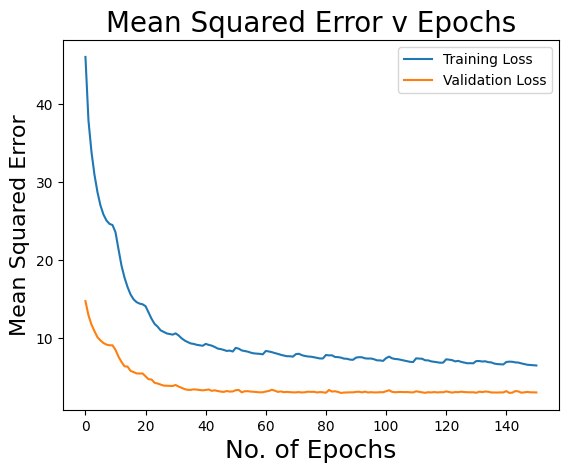

In [34]:
import matplotlib.pyplot as plt
num_epochs = 150
def my_plot(epochs, training_epoch_loss,valid_epoch_loss):
    plt.title('Mean Squared Error v Epochs', fontsize=20)
    plt.xlabel('No. of Epochs', fontsize=18)
    plt.ylabel('Mean Squared Error', fontsize=16)

    plt.plot(epochs, training_epoch_loss,label="Training Loss")
    plt.plot(epochs, valid_epoch_loss,label="Validation Loss")
    plt.legend()
#     plt.savefig('Model_3_128_AFLw_Test_ds.jpg')

my_plot(np.linspace(0, num_epochs, num_epochs).astype(int),train_losses,valid_losses)

In [35]:
# model.load_state_dict(torch.load(os.path.join(results_main_path,"model_saved_biwi_fan.pt")))
# model.eval()

In [36]:

test_loader_biwi=validate_loader



In [37]:
import torch
import pandas as pd

@torch.no_grad()
def evaluate_model(model, test_loader):
    device = next(model.parameters()).device
    model.eval()

    total_mae = torch.zeros(3, device=device)
    total_mse = torch.zeros(3, device=device)
    n = 0

    # store per-sample errors for boxplot
    all_yaw_err, all_pitch_err, all_roll_err = [], [], []

    for batch in test_loader:
        x = batch["landmark"].to(device)
        y = batch["pose"].to(device)       # (B,3)
        if torch.cuda.is_available():
            x, y = x.cuda(), y.cuda()
        yhat = model(x)



        err = yhat - y                     # (B,3)
        abs_err = err.abs()                # (B,3)

        # collect per-axis absolute errors
        all_yaw_err.extend(abs_err[:, 1].cpu().tolist())
        all_pitch_err.extend(abs_err[:, 0].cpu().tolist())
        all_roll_err.extend(abs_err[:, 2].cpu().tolist())

        total_mae += abs_err.sum(dim=0)
        total_mse += (err ** 2).sum(dim=0)
        n += y.size(0)
        #print(n)

    mae = (total_mae / n).tolist()
    print(n)
    print(mae)
    rmse = (total_mse / n).sqrt().tolist()

    metrics = {
        "MAE_per_axis":  {"yaw": mae[1], "pitch": mae[0], "roll": mae[2]},

        "MAE_mean": sum(mae) / 3,

    }

    # also return a DataFrame for visualization
    output_df = pd.DataFrame({
        "yaw_abs_error": all_yaw_err,
        "pitch_abs_error": all_pitch_err,
        "roll_abs_error": all_roll_err
    })

    return metrics, output_df


In [38]:
test_metrics, output_df = evaluate_model(model, test_loader_biwi)
print("BIWI")
print(test_metrics)


4587
[3.585007429122925, 2.823211193084717, 2.380959987640381]
BIWI
{'MAE_per_axis': {'yaw': 2.823211193084717, 'pitch': 3.585007429122925, 'roll': 2.380959987640381}, 'MAE_mean': 2.9297262032826743}


/tmp/ipykernel_7245/1107106438.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


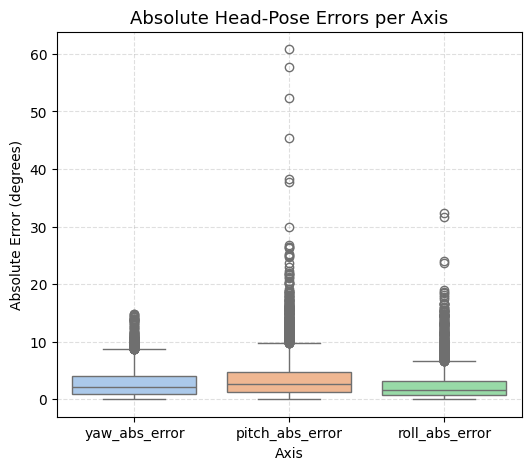

  YAW: 4587/4587  (100.00% within ±15°)
PITCH: 4496/4587  (98.02% within ±15°)
 ROLL: 4560/4587  (99.41% within ±15°)


In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# --- Boxplot ---
plt.figure(figsize=(6,5))
sns.boxplot(
    data=pd.melt(output_df, var_name="Axis", value_name="Absolute Error (°)"),
    x="Axis", y="Absolute Error (°)", palette="pastel"
)
plt.title("Absolute Head-Pose Errors per Axis", fontsize=13)
plt.ylabel("Absolute Error (degrees)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# --- Count of samples within ±15° ---
threshold = 15
total = output_df.shape[0]
for axis in ["yaw", "pitch", "roll"]:
    count = (output_df[f"{axis}_abs_error"] < threshold).sum()
    pct = 100 * count / total
    print(f"{axis.upper():>5}: {count}/{total}  ({pct:.2f}% within ±{threshold}°)")

In [40]:
from prettytable import PrettyTable

def count_parameters(model):
    table = PrettyTable(["Modules", "Parameters"])
    total_params = 0
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad: continue
        param = parameter.numel()
        table.add_row([name, param])
        total_params+=param
    print(table)
    print(f"Total Trainable Params: {total_params}")
    return total_params

count_parameters(model)

+--------------------------------+------------+
|            Modules             | Parameters |
+--------------------------------+------------+
|  deepsets.0.encoder.0.weight   |    192     |
|   deepsets.0.encoder.0.bias    |     64     |
|  deepsets.0.decoder.0.weight   |    4096    |
|   deepsets.0.decoder.0.bias    |     32     |
|  deepsets.1.encoder.0.weight   |    192     |
|   deepsets.1.encoder.0.bias    |     64     |
|  deepsets.1.decoder.0.weight   |    4096    |
|   deepsets.1.decoder.0.bias    |     32     |
|  deepsets.2.encoder.0.weight   |    192     |
|   deepsets.2.encoder.0.bias    |     64     |
|  deepsets.2.decoder.0.weight   |    4096    |
|   deepsets.2.decoder.0.bias    |     32     |
|  deepsets.3.encoder.0.weight   |    192     |
|   deepsets.3.encoder.0.bias    |     64     |
|  deepsets.3.decoder.0.weight   |    4096    |
|   deepsets.3.decoder.0.bias    |     32     |
|  deepsets.4.encoder.0.weight   |    192     |
|   deepsets.4.encoder.0.bias    |     6

44195

In [41]:
import torch
import pandas as pd

@torch.no_grad()
def evaluate_model(model, test_loader, save_path=None):
    device = next(model.parameters()).device
    model.eval()

    total_mae = torch.zeros(3, device=device)
    total_mse = torch.zeros(3, device=device)
    n = 0

    rows = []

    for batch in test_loader:

        x = batch["landmark"].to(device)
        y = batch["pose"].to(device)

        yhat = model(x)

        err = yhat - y
        abs_err = err.abs()

        total_mae += abs_err.sum(dim=0)
        total_mse += (err ** 2).sum(dim=0)
        n += y.size(0)

        gt = y.cpu().numpy()
        pred = yhat.cpu().numpy()
        e = err.cpu().numpy()
        ae = abs_err.cpu().numpy()

        for i in range(gt.shape[0]):
            rows.append({
                # Ground truth
                "gt_pitch": gt[i,0],
                "gt_yaw": gt[i,1],
                "gt_roll": gt[i,2],

                # Prediction
                "pred_pitch": pred[i,0],
                "pred_yaw": pred[i,1],
                "pred_roll": pred[i,2],

                # Signed error
                "pitch_error": e[i,0],
                "yaw_error": e[i,1],
                "roll_error": e[i,2],

                # Absolute error
                "pitch_abs_error": ae[i,0],
                "yaw_abs_error": ae[i,1],
                "roll_abs_error": ae[i,2],

                # Absolute pose angle
                "abs_pitch": abs(gt[i,0]),
                "abs_yaw": abs(gt[i,1]),
                "abs_roll": abs(gt[i,2]),
            })

    mae = (total_mae / n).tolist()
    rmse = (total_mse / n).sqrt().tolist()

    metrics = {
        "MAE_per_axis": {
            "yaw": mae[1],
            "pitch": mae[0],
            "roll": mae[2]
        },
        "RMSE_per_axis": {
            "yaw": rmse[1],
            "pitch": rmse[0],
            "roll": rmse[2]
        },
        "MAE_mean": sum(mae)/3
    }

    output_df = pd.DataFrame(rows)

    if save_path is not None:
        output_df.to_csv(save_path, index=False)

    return metrics, output_df

In [42]:
metrics, df = evaluate_model(
    model,
    test_loader_biwi,
    save_path="fan_biwi_biwi.csv"
)

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [44]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

@torch.no_grad()
def collect_current_model_predictions(model, test_loader):
    device = next(model.parameters()).device
    model.eval()

    rows = []

    for batch in test_loader:
        x = batch["landmark"].to(device)
        y = batch["pose"].to(device)   # expected order: pitch, yaw, roll

        yhat = model(x)

        err = yhat - y
        abs_err = err.abs()

        gt = y.detach().cpu().numpy()
        pred = yhat.detach().cpu().numpy()
        ae = abs_err.detach().cpu().numpy()

        for i in range(gt.shape[0]):
            rows.append({
                "gt_pitch": gt[i, 0],
                "gt_yaw": gt[i, 1],
                "gt_roll": gt[i, 2],

                "pred_pitch": pred[i, 0],
                "pred_yaw": pred[i, 1],
                "pred_roll": pred[i, 2],

                "pitch_abs_error": ae[i, 0],
                "yaw_abs_error": ae[i, 1],
                "roll_abs_error": ae[i, 2],

                "abs_pitch": abs(gt[i, 0]),
                "abs_yaw": abs(gt[i, 1]),
                "abs_roll": abs(gt[i, 2]),
            })

    return pd.DataFrame(rows)


df = collect_current_model_predictions(model, test_loader_biwi)
df.head()

,gt_pitch,gt_yaw,gt_roll,pred_pitch,pred_yaw,pred_roll,pitch_abs_error,yaw_abs_error,roll_abs_error,abs_pitch,abs_yaw,abs_roll
0,25.042171,-48.496059,-7.064634,31.233395,-53.499149,-13.069148,6.191223,5.003090,6.004514,25.042171,48.496059,7.064634
1,13.729471,7.107767,-0.524694,10.998013,8.964546,-0.152652,2.731459,1.856780,0.372042,13.729471,7.107767,0.524694
2,-18.885950,67.169685,-19.718000,-16.248674,59.613068,-16.129429,2.637276,7.556618,3.588572,18.885950,67.169685,19.718000
3,2.234311,65.585915,-2.415471,17.880722,62.197563,8.007027,15.646411,3.388351,10.422498,2.234311,65.585915,2.415471
4,39.282433,50.915455,21.356998,34.223667,44.041588,17.349926,5.058765,6.873867,4.007072,39.282433,50.915455,21.356998


In [45]:
def plot_mae_vs_gt_angle(df, angle_name, bin_width=15):
    gt_col = f"gt_{angle_name}"
    err_col = f"{angle_name}_abs_error"

    min_angle = np.floor(df[gt_col].min() / bin_width) * bin_width
    max_angle = np.ceil(df[gt_col].max() / bin_width) * bin_width
    bins = np.arange(min_angle, max_angle + bin_width, bin_width)

    temp = df.copy()
    temp["angle_bin"] = pd.cut(temp[gt_col], bins=bins, include_lowest=True)

    binned = (
        temp.groupby("angle_bin", observed=True)
        .agg(
            mae=(err_col, "mean"),
            count=(err_col, "count")
        )
        .reset_index()
    )

    binned["bin_center"] = binned["angle_bin"].apply(
        lambda x: (x.left + x.right) / 2
    )

    plt.figure(figsize=(7, 4.5))
    plt.plot(binned["bin_center"], binned["mae"], marker="o")
    plt.xlabel(f"Ground-truth {angle_name.capitalize()} Angle (degrees)")
    plt.ylabel("Mean Absolute Error (degrees)")
    plt.title(f"MAE vs Ground-truth {angle_name.capitalize()} Angle")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return binned

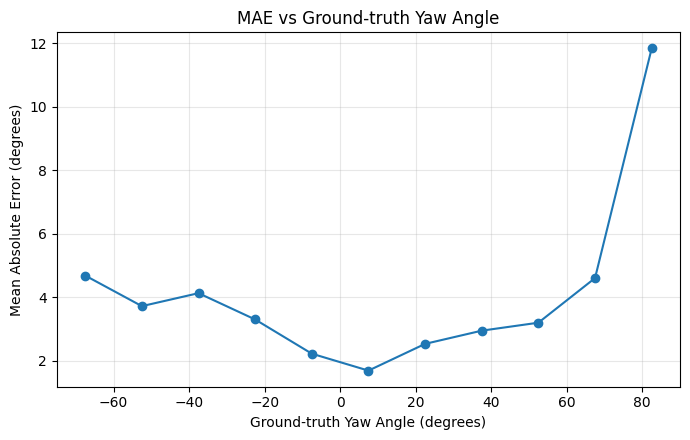

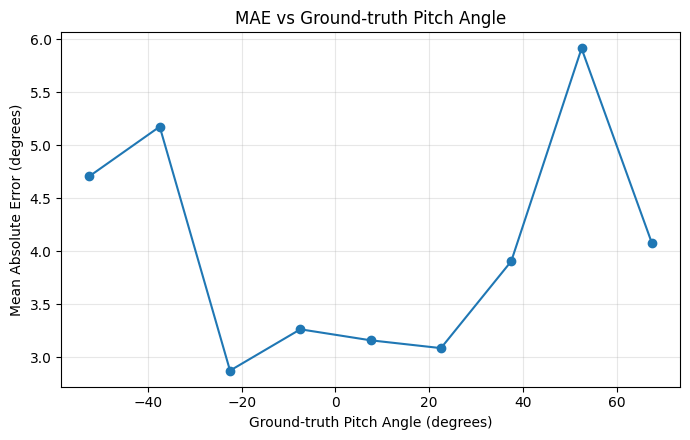

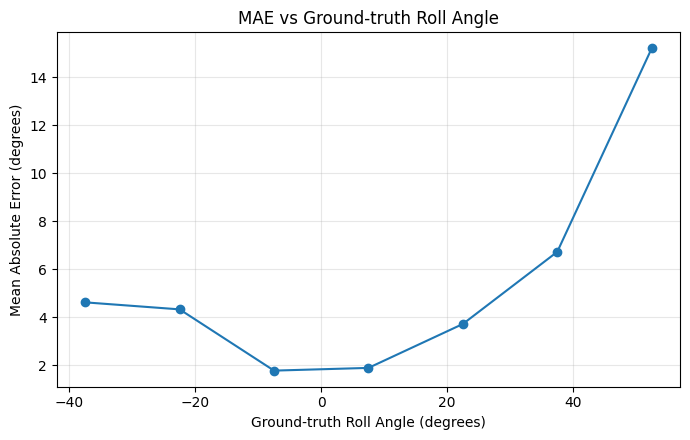

In [46]:
yaw_gt_bins = plot_mae_vs_gt_angle(df, "yaw")
pitch_gt_bins = plot_mae_vs_gt_angle(df, "pitch")
roll_gt_bins = plot_mae_vs_gt_angle(df, "roll")

In [47]:
def plot_mae_vs_abs_angle(df, angle_name, bin_width=15):
    abs_col = f"abs_{angle_name}"
    err_col = f"{angle_name}_abs_error"

    max_angle = np.ceil(df[abs_col].max() / bin_width) * bin_width
    bins = np.arange(0, max_angle + bin_width, bin_width)

    temp = df.copy()
    temp["abs_angle_bin"] = pd.cut(temp[abs_col], bins=bins, include_lowest=True)

    binned = (
        temp.groupby("abs_angle_bin", observed=True)
        .agg(
            mae=(err_col, "mean"),
            count=(err_col, "count")
        )
        .reset_index()
    )

    binned["bin_center"] = binned["abs_angle_bin"].apply(
        lambda x: (x.left + x.right) / 2
    )

    plt.figure(figsize=(7, 4.5))
    plt.plot(binned["bin_center"], binned["mae"], marker="o")
    plt.xlabel(f"Absolute Ground-truth {angle_name.capitalize()} Angle (degrees)")
    plt.ylabel("Mean Absolute Error (degrees)")
    plt.title(f"MAE vs Absolute {angle_name.capitalize()} Angle")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return binned

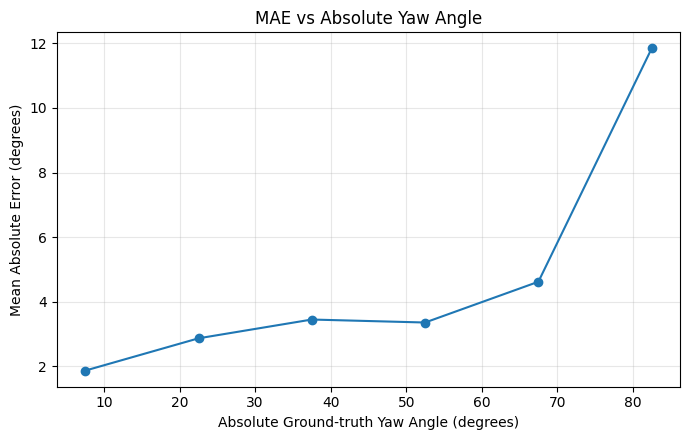

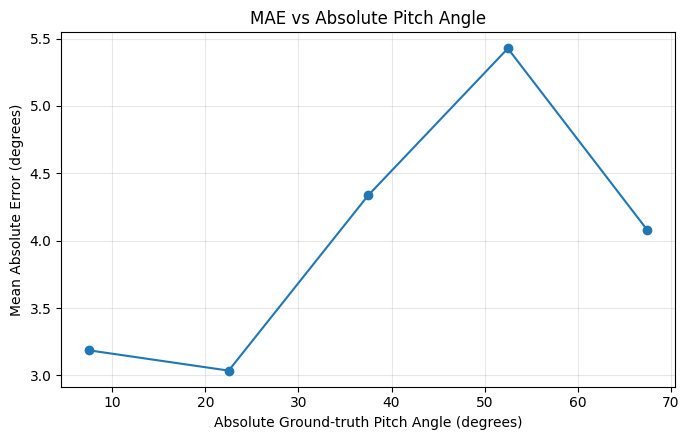

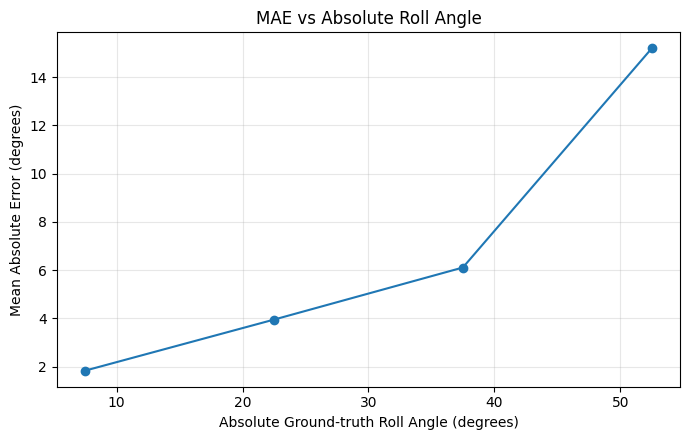

In [48]:
yaw_abs_bins = plot_mae_vs_abs_angle(df, "yaw")
pitch_abs_bins = plot_mae_vs_abs_angle(df, "pitch")
roll_abs_bins = plot_mae_vs_abs_angle(df, "roll")

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_error_boxplot(df, angle="yaw", bin_width=15):
    """
    angle : 'yaw', 'pitch', or 'roll'
    """

    abs_angle = df[f"abs_{angle}"]
    error = df[f"{angle}_abs_error"]

    max_angle = np.ceil(abs_angle.max()/bin_width)*bin_width

    bins = np.arange(0, max_angle + bin_width, bin_width)

    labels = [
        f"{int(bins[i])}-{int(bins[i+1])}"
        for i in range(len(bins)-1)
    ]

    temp = df.copy()
    temp["Angle Range"] = pd.cut(
        abs_angle,
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    grouped = [
        temp[temp["Angle Range"] == label][f"{angle}_abs_error"]
        for label in labels
    ]

    plt.figure(figsize=(8,5))

    plt.boxplot(
        grouped,
        labels=labels,
        showfliers=True,
        widths=0.6
    )

    plt.xlabel(f"Absolute {angle.capitalize()} Angle (degrees)")
    plt.ylabel("Absolute Error (degrees)")
    plt.title(f"{angle.capitalize()} Error Distribution")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_7245/2287479999.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


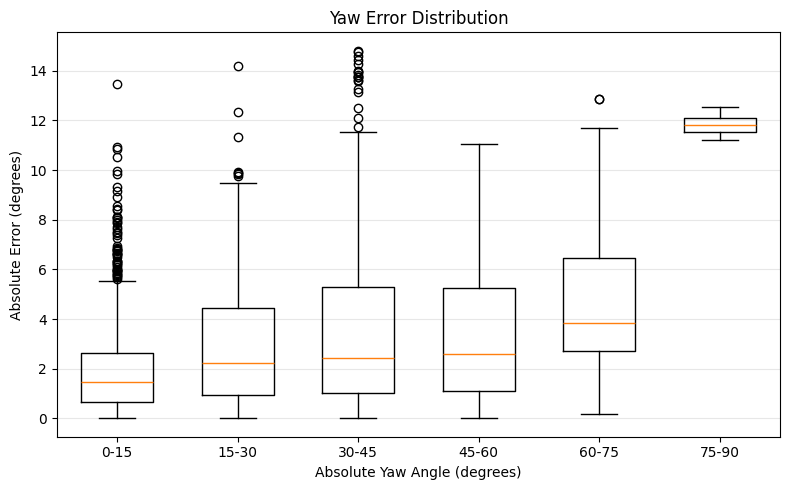

/tmp/ipykernel_7245/2287479999.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


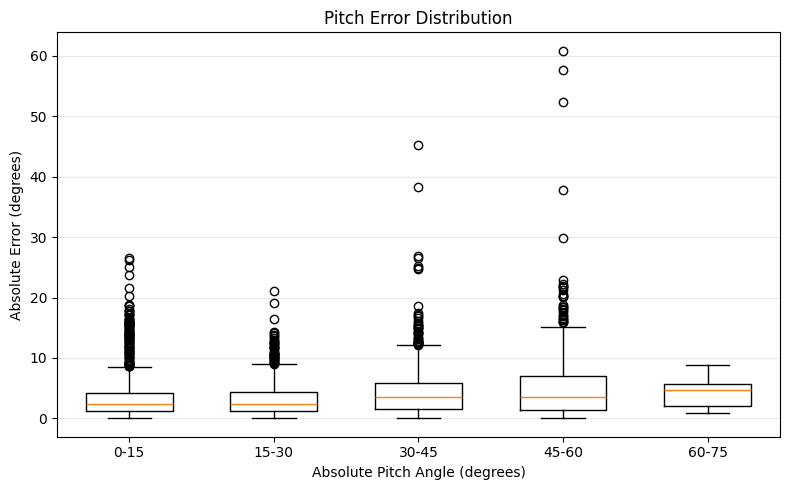

/tmp/ipykernel_7245/2287479999.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


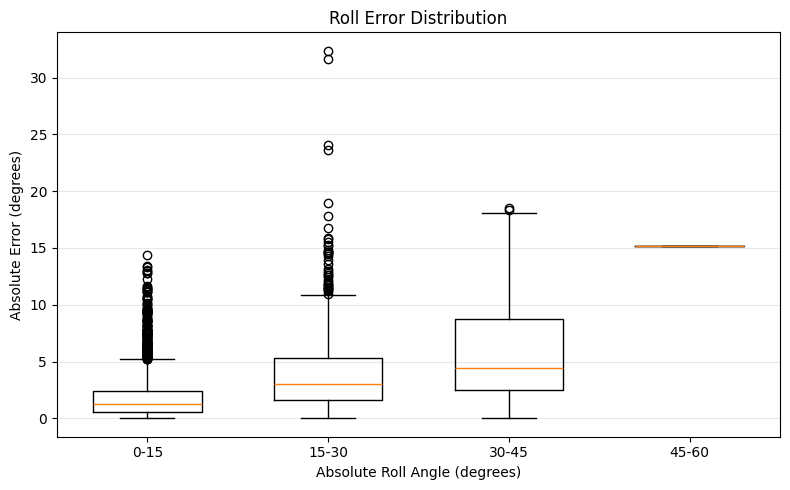

In [50]:
plot_error_boxplot(df, "yaw")

plot_error_boxplot(df, "pitch")

plot_error_boxplot(df, "roll")